# Gaps between primes

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapter "Further questions about primes".*

> In celebration of Yitang Zhang's recent result, let us consider more of the numerics regarding *gaps* between one prime and the next, rather than the tally of all primes.

The book defines
$$\operatorname{Gap}_k(X)$$
> to be the number of pairs of *consecutive* primes $(p,q)$ with $q<X$ that have "gap $k$" (i.e., such that their difference $q-p$ is $k$). Here $p$ is a prime, $q>p$ is a prime, and there are no primes between $p$ and $q$.

In this notebook you will recompute the book's table of $\operatorname{Gap}_k(X)$, see which gaps are most common, run the book's race between gaps $2$, $4$, $6$ and $8$, check the Hardy–Littlewood conjecture that predicts its outcome, and look at the sizes of gaps relative to $\log p$, where a simple random model fits remarkably well.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def primes_upto(X):
    "The primes up to X, as an array."
    return np.array(prime_range(X + 1), dtype=np.int64)

def Gap(k, X):
    "Gap_k(X): pairs of consecutive primes p < q < X with q - p = k."
    P = primes_upto(X - 1)
    return int(np.count_nonzero(np.diff(P) == k))

print([Gap(2, 10), Gap(4, 10)])   # the book's examples: (3,5), (5,7); and none

[2, 0]


## 1. The book's table, recomputed

The book lists $\operatorname{Gap}_k(X)$ for $X$ up to $10^8$ and $k = 2, 4, 6, 8, 100, 246$. Here it is, computed live (up to $10^7$ by default; choose $10^8$ for the book's last row, which takes a little longer).

In [2]:
@interact
def gap_table(largest=selector([10^6, 10^7, 10^8], default=10^7, label='largest X')):
    ks = [2, 4, 6, 8, 100, 246]
    rows = [['X'] + ['Gap_%d(X)' % k for k in ks]]
    P = primes_upto(largest)
    for e in range(1, int(log(largest, 10)) + 1):
        X = 10^e
        g = np.diff(P[P < X])
        rows.append(['10^%d' % e] + [int(np.count_nonzero(g == k)) for k in ks])
    print(table(rows, header_row=True))

  X      Gap_2(X)   Gap_4(X)   Gap_6(X)   Gap_8(X)   Gap_100(X)   Gap_246(X)
├──────┼──────────┼──────────┼──────────┼──────────┼────────────┼────────────┤
  10^1   2          0          0          0          0            0
  10^2   8          7          7          1          0            0
  10^3   35         40         44         15         0            0
  10^4   205        202        299        101        0            0
  10^5   1224       1215       1940       773        0            0
  10^6   8169       8143       13549      5569       2            0
  10^7   58980      58621      99987      42352      36           0


The book's comment on the last column:

> The recent results of Zhang as sharpened by Maynard (and others) we mentioned above tell us that for at least one even number $k$ among the even numbers $k \le 246$, $\operatorname{Gap}_{k}(X)$ goes to infinity as $X$ goes to infinity. One expects that this happens for *all* even numbers $k$. We expect this as well, of course, for $\operatorname{Gap}_{246}(X)$ despite what might be misconstrued as discouragement by the above data.

## 2. Which gaps are most common?

The book's figure: the frequency of each gap among the primes up to $10^7$. "Six is the most popular gap in this data." Is it at every scale? Change $X$. (For small $X$ the gaps $2$ and $4$ compete with $6$. It is conjectured that $6$ stays the most common gap until about $1.7 \times 10^{35}$, when $30$ takes over, and later $210$, the products of the first primes: the "jumping champions".)

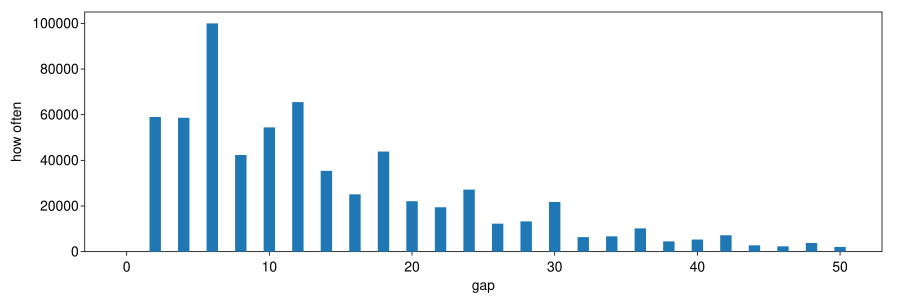

most common gap up to 10000000: 6 (99987 times); largest gap: 154


In [3]:
@interact
def gap_histogram(X=selector([10^3, 10^4, 10^5, 10^6, 10^7], default=10^7, label='primes up to'),
                  largest=slider(10, 100, 2, 50, label='largest gap shown')):
    g = np.diff(primes_upto(X))
    counts = np.bincount(g, minlength=largest + 1)[:largest + 1]
    plt.figure(figsize=(9, 3))
    plt.bar(np.arange(largest + 1), counts, color='tab:blue')
    plt.xlabel('gap')
    plt.ylabel('how often')
    plt.show()
    champion = int(np.argmax(np.bincount(g)))
    print('most common gap up to %d: %d (%d times); largest gap: %d' % (X, champion, int(np.bincount(g)[champion]), int(g.max())))

## 3. The race: $\operatorname{Gap}_2$, $\operatorname{Gap}_4$, $\operatorname{Gap}_6$, $\operatorname{Gap}_8$

> Challenge: As $X$ tends to infinity which of $\operatorname{Gap}_2(X)$, $\operatorname{Gap}_4(X)$, $\operatorname{Gap}_6(X)$, or $\operatorname{Gap}_8(X)$ do you think will grow faster? How much would you bet on the truth of your guess?

Run the race as far as you like, and choose which gaps compete.

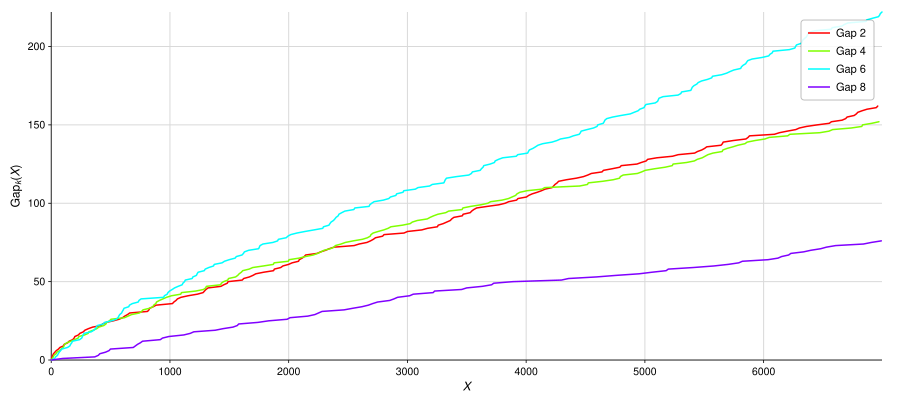

In [4]:
@interact
def race(X=selector([7000, 10^5, 10^6, 10^7], default=7000, label='X'),
         gaps=selector(['2, 4, 6, 8', '2, 4, 6, 8, 10, 12', '6, 30'], label='gaps')):
    ks = [int(k) for k in gaps.split(',')]
    P = primes_upto(X)
    g = np.diff(P)
    q = P[1:]
    picture = Graphics()
    for i, k in enumerate(ks):
        at = q[g == k]
        steps = list(zip(at, np.arange(1, len(at) + 1)))
        if steps:
            picture += line([(0, 0)] + steps, color=hue(i / len(ks)), legend_label='Gap %d' % k)
    show(picture, axes_labels=['$X$', r'$\mathrm{Gap}_k(X)$'], figsize=[9, 4], gridlines=True)

## 4. The Hardy–Littlewood answer

The book's endnote points to Hardy and Littlewood's conjecture. It is about $P_k(X)$, the number of primes $p \le X$ such that $p + k$ is also prime (not necessarily the next prime), and predicts, for even $k$,
$$P_k(X) \;\approx\; 2C_2 \prod_{\substack{p \mid k\\ p > 2}} \frac{p-1}{p-2}\; \int_2^X \frac{dt}{(\log t)^2},$$
where $C_2 = \prod_{p > 2}\left(1 - \frac{1}{(p-1)^2}\right) \approx 0.6601618$ is the twin prime constant. So $k = 6$ (divisible by $3$) gets a factor $\frac{3-1}{3-2} = 2$, $k = 30$ gets $2 \cdot \frac{4}{3} = \frac{8}{3}$, and $k = 2, 4, 8$ all get $1$. That is why $6$ wins the race, and $2$ and $4$ run neck and neck.

The table compares the actual $P_k(X)$ with the prediction. (Note $\int_2^X dt/(\log t)^2 = \operatorname{Li}(X) - X/\log X + 2/\log 2$, by parts.)

In [5]:
from scipy.special import expi
C2 = 0.6601618158468695739

def hardy_littlewood(k, X):
    "Hardy and Littlewood's prediction for the number of primes p <= X with p + k prime."
    factor = 2 * C2 * prod((p - 1) / (p - 2) for p in prime_divisors(k) if p > 2)
    integral = expi(float(log(X))) - expi(float(log(2))) - X / float(log(X)) + 2 / float(log(2))
    return factor * integral

@interact
def check_hardy_littlewood(X=selector([10^5, 10^6, 10^7], default=10^6, label='X')):
    is_prime = np.zeros(X + 31, dtype=bool)
    is_prime[np.array(prime_range(X + 31))] = True
    P = primes_upto(X)
    rows = [['k', 'P_k(X)', 'prediction', 'ratio']]
    for k in [2, 4, 6, 8, 10, 12, 30]:
        actual = int(np.count_nonzero(is_prime[P + k]))
        predicted = hardy_littlewood(k, X)
        rows.append([k, actual, '%.0f' % predicted, '%.4f' % (actual / predicted)])
    print(table(rows, header_row=True))

  k    P_k(X)   prediction   ratio
├────┼────────┼────────────┼────────┤
  2    8169     8248         0.9904
  4    8144     8248         0.9874
  6    16386    16496        0.9933
  8    8242     8248         0.9993
  10   10934    10997        0.9942
  12   16378    16496        0.9928
  30   21990    21995        0.9998


## 5. How big are the gaps? Gaps relative to $\log p$

Near $p$ the primes have density about $1/\log p$, so the average gap there is about $\log p$. If primes behaved like random numbers chosen with probability $1/\log n$ (Cramér's model), the normalized gaps $(q-p)/\log p$ would follow the exponential distribution, with density $e^{-x}$. The worksheets behind the book's figures looked at three normalizations: $(q-p)/p$, $(q-p)/\log p$ and $(q-p)/\sqrt{\log p}$. Compare them here; for $\log p$ the red curve is $e^{-x}$.

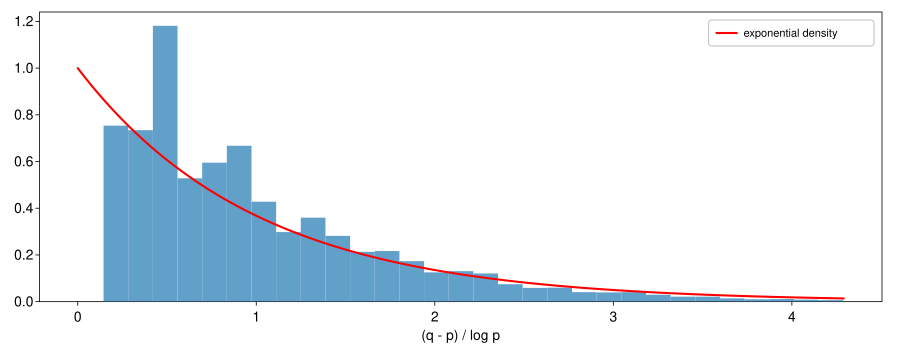

mean 1.0017, median 0.7806


In [6]:
NORMALIZE = {
    '(q - p) / log p': lambda P: np.diff(P) / np.log(P[:-1]),
    '(q - p) / sqrt(log p)': lambda P: np.diff(P) / np.sqrt(np.log(P[:-1])),
    '(q - p) / p': lambda P: np.diff(P) / P[:-1],
}

@interact
def normalized_gaps(X=selector([10^5, 10^6, 10^7], default=10^6, label='primes up to'),
                    how=selector(list(NORMALIZE), label='divide the gap by'),
                    bins=slider(10, 200, 10, 30, label='bins')):
    P = primes_upto(X).astype(float)
    g = NORMALIZE[how](P)
    plt.figure(figsize=(9, 3.5))
    top = np.quantile(g, 0.995)
    plt.hist(g[g <= top], bins=bins, density=True, color='tab:blue', alpha=0.7)
    if how == '(q - p) / log p':
        t = np.linspace(0, top, 300)
        plt.plot(t, np.exp(-t), 'r', label='exponential density')
        plt.legend()
    plt.xlabel(how)
    plt.show()
    print('mean %.4f, median %.4f' % (g.mean(), np.median(g)))

The fit for $(q-p)/\log p$ is good but not perfect: gaps are always even, and small gaps are rarer than the model says because of the "conspiracies" (divisibility by $3$, $5$, …) that the Hardy–Littlewood factors measure.

## Things to try

1. Find the first pair of consecutive primes with gap $100$, and with gap $246$ (the book's table shows none up to $10^8$ for $246$). How far do you have to go?
2. In section 3, race gaps $6$ and $30$. Who leads up to $10^7$? The Hardy–Littlewood factors predict $30$ eventually wins: by how much should it be behind now?
3. In section 4, add $k = 210$. What factor does the conjecture give, and how well does it fit?
4. The largest gap below $X$ seems to be about $(\log X)^2$ (Cramér's conjecture). Compute the record gaps up to $10^7$ and compare.

---
*Adapted and greatly expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*